In [1]:
!nvidia-smi

Mon Apr 27 01:37:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8             16W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip install -q diffusers==0.27.2 accelerate==0.30.1 torchvision==0.18.0 datasets==2.19.0 matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 81.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.6/302.6 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 115.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.0/542.0 kB 50.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 779.1/779.1 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 106.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 82.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [2]:
!pip install -q --upgrade diffusers accelerate huggingface_hub

In [3]:
import torch, torch.nn.functional as F
from diffusers import UNet2DModel, DDPMScheduler, DDIMScheduler
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

import diffusers
print(f"Diffusers version: {diffusers.__version__}")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Device: cuda
Diffusers version: 0.37.1


100%|██████████| 170498071/170498071 [00:13<00:00, 12858532.52it/s]


Extracting ./data/cifar-10-python.tar.gz to ./data
Dataset size: 50000
Batches per epoch: 390
Batch shape: torch.Size([128, 3, 32, 32]), range: [-1.00, 1.00]


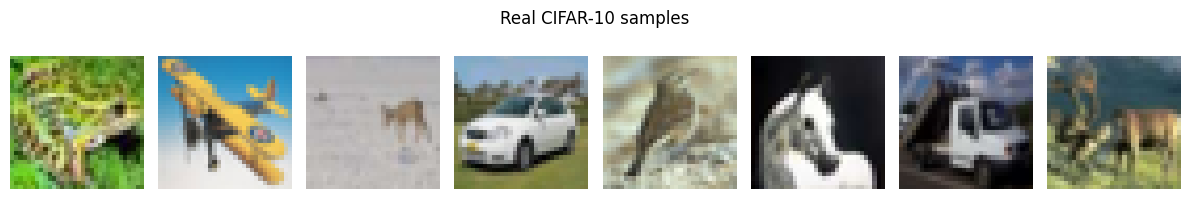

In [4]:
Path("samples").mkdir(exist_ok=True)
Path("checkpoints").mkdir(exist_ok=True)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda t: (t * 2) - 1),
])
trainset = datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
loader = DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2, drop_last=True)

print(f"Dataset size: {len(trainset)}")
print(f"Batches per epoch: {len(loader)}")

batch, _ = next(iter(loader))
print(f"Batch shape: {batch.shape}, range: [{batch.min():.2f}, {batch.max():.2f}]")

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    img = (batch[i] + 1) / 2
    ax.imshow(img.permute(1, 2, 0).cpu().numpy())
    ax.axis("off")
plt.suptitle("Real CIFAR-10 samples")
plt.tight_layout()
plt.savefig("samples/real_cifar10.png", dpi=120, bbox_inches="tight")
plt.show()

In [5]:
model = UNet2DModel(
    sample_size=32,
    in_channels=3, out_channels=3,
    layers_per_block=2,
    block_out_channels=(64, 128, 256, 256),
    down_block_types=("DownBlock2D", "DownBlock2D", "DownBlock2D", "DownBlock2D"),
    up_block_types=("UpBlock2D", "UpBlock2D", "UpBlock2D", "UpBlock2D"),
).to(device)

scheduler = DDPMScheduler(num_train_timesteps=1000, beta_schedule="squaredcos_cap_v2")
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"Model parameters: {n_params:.2f}M")
print(f"Scheduler timesteps: {scheduler.config.num_train_timesteps}")
print(f"Beta schedule: {scheduler.config.beta_schedule}")

Model parameters: 23.99M
Scheduler timesteps: 1000
Beta schedule: squaredcos_cap_v2


Epoch 1/10:   0%|          | 0/390 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:744: UserWarning: Plan failed with a cudnnException: CUDNN_BACKEND_EXECUTION_PLAN_DESCRIPTOR: cudnnFinalize Descriptor Failed cudnn_status: CUDNN_STATUS_NOT_SUPPORTED (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:919.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Epoch 1/10: loss = 0.1470  |  elapsed: 2.4 min


Epoch 2/10:   0%|          | 0/390 [00:00<?, ?it/s]

Epoch 2/10: loss = 0.0816  |  elapsed: 4.8 min
  ↳ checkpoint saved


Epoch 3/10:   0%|          | 0/390 [00:00<?, ?it/s]

... (12 outputs left out)

Epoch 9/10: loss = 0.0643  |  elapsed: 22.4 min


Epoch 10/10:   0%|          | 0/390 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7844f033d800>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1479, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1462, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process


Epoch 10/10: loss = 0.0629  |  elapsed: 25.0 min
  ↳ checkpoint saved


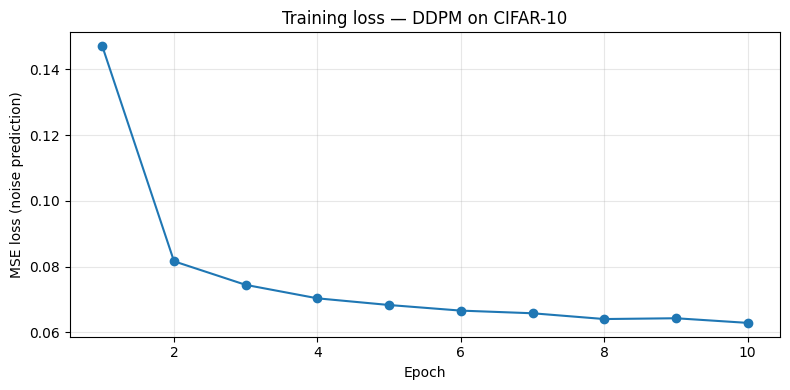


Final loss: 0.0629
Total training time: 25.0 min


In [6]:
from tqdm.auto import tqdm
import time

n_epochs = 10
losses = []
training_start = time.time()

for epoch in range(n_epochs):
    epoch_losses = []
    for batch, _ in tqdm(loader, desc=f"Epoch {epoch+1}/{n_epochs}", leave=False):
        batch = batch.to(device)
        noise = torch.randn_like(batch)
        timesteps = torch.randint(
            0, scheduler.config.num_train_timesteps,
            (batch.size(0),), device=device
        ).long()
        noisy = scheduler.add_noise(batch, noise, timesteps)
        pred = model(noisy, timesteps).sample
        loss = F.mse_loss(pred, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_losses.append(loss.item())

    avg_loss = float(np.mean(epoch_losses))
    losses.append(avg_loss)
    elapsed = time.time() - training_start
    print(f"Epoch {epoch+1}/{n_epochs}: loss = {avg_loss:.4f}  |  elapsed: {elapsed/60:.1f} min")

    # Checkpoint every 2 epochs as safety net
    if (epoch + 1) % 2 == 0:
        torch.save(
            {"model_state": model.state_dict(),
             "optimizer_state": optimizer.state_dict(),
             "epoch": epoch + 1,
             "losses": losses},
            f"checkpoints/ddpm_cifar10_ep{epoch+1}.pt",
        )
        print(f"  ↳ checkpoint saved")

# Final loss curve
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(losses)+1), losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (noise prediction)")
plt.title("Training loss — DDPM on CIFAR-10")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("samples/loss_curve.png", dpi=120, bbox_inches="tight")
plt.show()

# Final checkpoint
torch.save(
    {"model_state": model.state_dict(),
     "optimizer_state": optimizer.state_dict(),
     "epoch": n_epochs,
     "losses": losses},
    "checkpoints/ddpm_cifar10_final.pt",
)
print(f"\nFinal loss: {losses[-1]:.4f}")
print(f"Total training time: {(time.time()-training_start)/60:.1f} min")

DDPM 1000-step:   0%|          | 0/1000 [00:00<?, ?it/s]

DDPM 1000-step: 19.0s for 8 samples


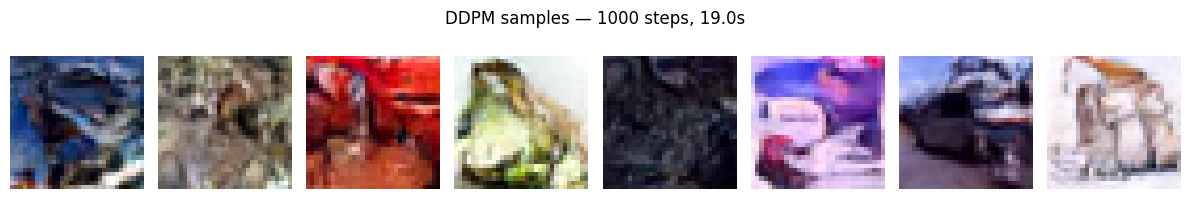

In [7]:
@torch.no_grad()
def sample_ddpm(model, scheduler, n_samples=8, n_steps=1000):
    model.eval()
    scheduler.set_timesteps(n_steps)
    x = torch.randn(n_samples, 3, 32, 32, device=device)
    for t in tqdm(scheduler.timesteps, desc=f"DDPM {n_steps}-step"):
        pred_noise = model(x, t).sample
        x = scheduler.step(pred_noise, t, x).prev_sample
    return x

t0 = time.time()
samples_ddpm = sample_ddpm(model, scheduler, n_samples=8, n_steps=1000)
ddpm_time = time.time() - t0
print(f"DDPM 1000-step: {ddpm_time:.1f}s for 8 samples")

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    img = (samples_ddpm[i].clamp(-1, 1) + 1) / 2
    ax.imshow(img.permute(1, 2, 0).cpu().numpy())
    ax.axis("off")
plt.suptitle(f"DDPM samples — 1000 steps, {ddpm_time:.1f}s")
plt.tight_layout()
plt.savefig("samples/ddpm_1000steps.png", dpi=120, bbox_inches="tight")
plt.show()

DDIM 50-step:   0%|          | 0/50 [00:00<?, ?it/s]

DDIM   50-step:   1.0s for 8 samples  (20× fewer evals than DDPM)


DDIM 100-step:   0%|          | 0/100 [00:00<?, ?it/s]

DDIM  100-step:   1.8s for 8 samples  (10× fewer evals than DDPM)


DDIM 250-step:   0%|          | 0/250 [00:00<?, ?it/s]

DDIM  250-step:   4.6s for 8 samples  (4× fewer evals than DDPM)


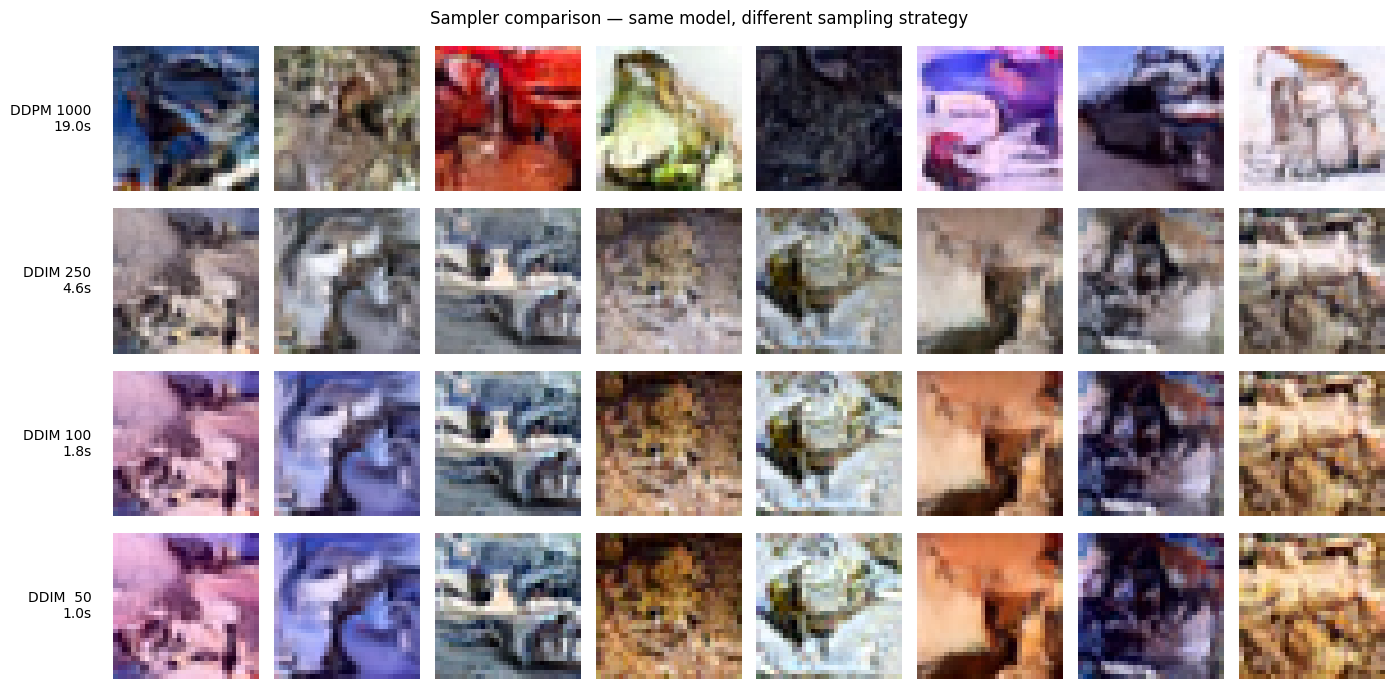

In [8]:
ddim_scheduler = DDIMScheduler.from_config(scheduler.config)

@torch.no_grad()
def sample_ddim(model, ddim_sched, n_samples=8, n_steps=50):
    model.eval()
    ddim_sched.set_timesteps(n_steps)
    x = torch.randn(n_samples, 3, 32, 32, device=device)
    for t in tqdm(ddim_sched.timesteps, desc=f"DDIM {n_steps}-step", leave=False):
        pred_noise = model(x, t).sample
        x = ddim_sched.step(pred_noise, t, x).prev_sample
    return x

# Sample at three step counts so we can show the quality/speed tradeoff
results = {}
for n_steps in [50, 100, 250]:
    torch.manual_seed(42)  # same noise seed → comparable samples
    t0 = time.time()
    s = sample_ddim(model, ddim_scheduler, n_samples=8, n_steps=n_steps)
    elapsed = time.time() - t0
    results[n_steps] = (s, elapsed)
    print(f"DDIM {n_steps:4d}-step: {elapsed:5.1f}s for 8 samples  ({1000/n_steps:.0f}× fewer evals than DDPM)")

# 4-row comparison grid: DDPM 1000 vs DDIM 250/100/50
configs = [
    ("DDPM 1000", samples_ddpm, ddpm_time),
    ("DDIM 250",  results[250][0], results[250][1]),
    ("DDIM 100",  results[100][0], results[100][1]),
    ("DDIM  50",  results[50][0],  results[50][1]),
]

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for row, (name, samp, elapsed) in enumerate(configs):
    for col in range(8):
        img = (samp[col].clamp(-1, 1) + 1) / 2
        axes[row, col].imshow(img.permute(1, 2, 0).cpu().numpy())
        axes[row, col].axis("off")
    axes[row, 0].text(
        -0.15, 0.5,
        f"{name}\n{elapsed:.1f}s",
        transform=axes[row, 0].transAxes,
        ha="right", va="center", fontsize=10,
    )

plt.suptitle("Sampler comparison — same model, different sampling strategy", fontsize=12)
plt.tight_layout()
plt.savefig("samples/scheduler_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

DDIM eta=0.5:   0%|          | 0/100 [00:00<?, ?it/s]

DDIM 100-step eta=0.5: 4.8s


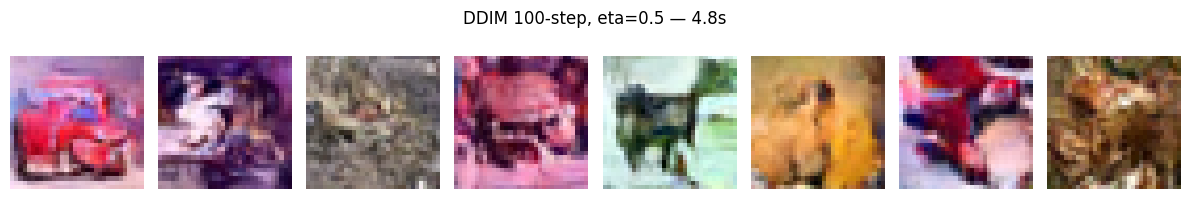

In [9]:
@torch.no_grad()
def sample_ddim_eta(model, ddim_sched, n_samples=8, n_steps=100, eta=0.5):
    model.eval()
    ddim_sched.set_timesteps(n_steps)
    x = torch.randn(n_samples, 3, 32, 32, device=device)
    for t in tqdm(ddim_sched.timesteps, desc=f"DDIM eta={eta}", leave=False):
        pred_noise = model(x, t).sample
        x = ddim_sched.step(pred_noise, t, x, eta=eta).prev_sample
    return x

torch.manual_seed(42)
t0 = time.time()
samples_eta05 = sample_ddim_eta(model, ddim_scheduler, n_samples=8, n_steps=100, eta=0.5)
eta_time = time.time() - t0
print(f"DDIM 100-step eta=0.5: {eta_time:.1f}s")

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    img = (samples_eta05[i].clamp(-1, 1) + 1) / 2
    ax.imshow(img.permute(1, 2, 0).cpu().numpy())
    ax.axis("off")
plt.suptitle(f"DDIM 100-step, eta=0.5 — {eta_time:.1f}s")
plt.tight_layout()
plt.savefig("samples/ddim_eta05.png", dpi=120, bbox_inches="tight")
plt.show()

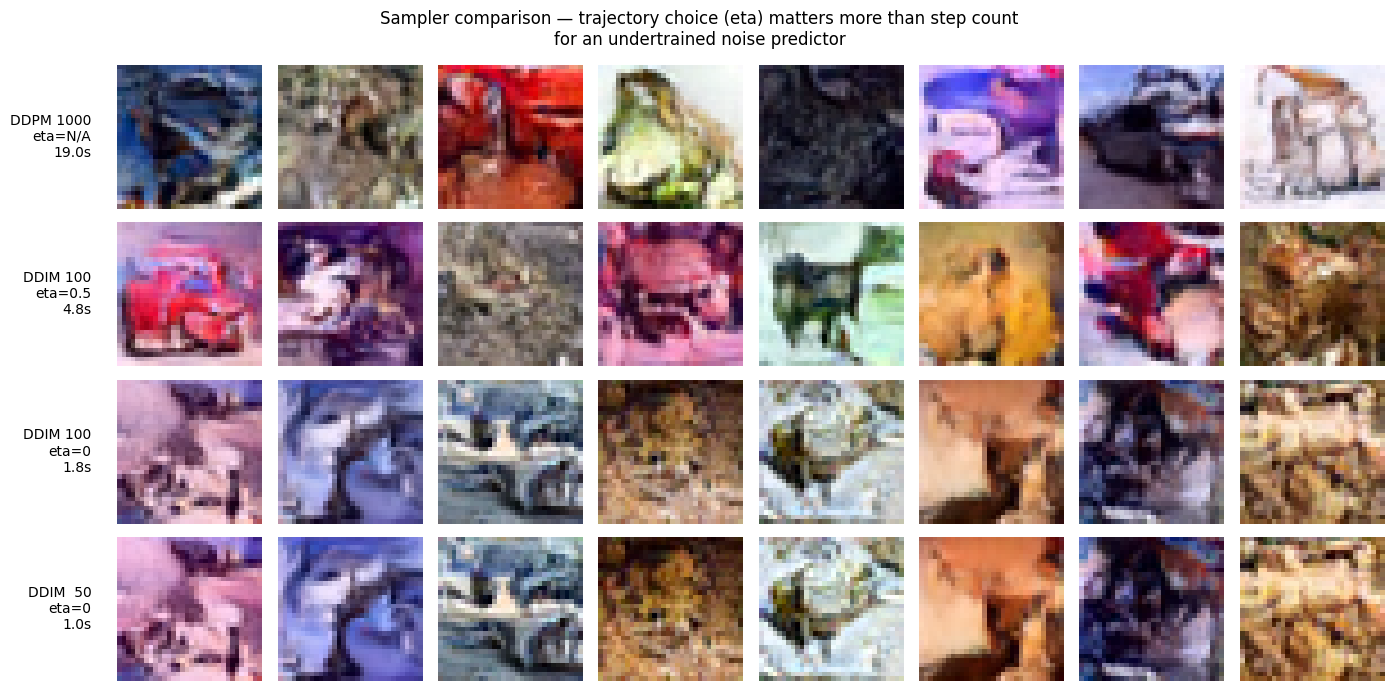

In [10]:
configs = [
    ("DDPM 1000\neta=N/A",     samples_ddpm,       ddpm_time),
    ("DDIM 100\neta=0.5",      samples_eta05,      eta_time),
    ("DDIM 100\neta=0",        results[100][0],    results[100][1]),
    ("DDIM  50\neta=0",        results[50][0],     results[50][1]),
]

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for row, (name, samp, elapsed) in enumerate(configs):
    for col in range(8):
        img = (samp[col].clamp(-1, 1) + 1) / 2
        axes[row, col].imshow(img.permute(1, 2, 0).cpu().numpy())
        axes[row, col].axis("off")
    axes[row, 0].text(
        -0.18, 0.5,
        f"{name}\n{elapsed:.1f}s",
        transform=axes[row, 0].transAxes,
        ha="right", va="center", fontsize=10,
    )

plt.suptitle(
    "Sampler comparison — trajectory choice (eta) matters more than step count\n"
    "for an undertrained noise predictor",
    fontsize=12,
)
plt.tight_layout()
plt.savefig("samples/scheduler_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

In [11]:
import shutil
shutil.make_archive("tiny_diffusion_outputs", "zip", ".", "samples")
print("Archive contents:")
import zipfile
with zipfile.ZipFile("tiny_diffusion_outputs.zip") as z:
    for name in z.namelist():
        print(f"  {name}")

Archive contents:
  samples/
  samples/ddpm_1000steps.png
  samples/scheduler_comparison.png
  samples/real_cifar10.png
  samples/ddim_eta05.png
  samples/loss_curve.png


In [12]:
from google.colab import files
files.download("tiny_diffusion_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>